# A1 - Data exploration and analysis (LIAR + ISOT)

**Owner:** Member 1 (data & evaluation)

This notebook covers **A1 only**: exploring both datasets and building the splits.
(A2 and A6 are done in a separate notebook.)

The notebook is in two parts so each dataset can be read on its own:

- **Part 1 - LIAR** (sections 1.1 to 1.9). Every exploration function is **defined here**, the first time it is used.
- **Part 2 - ISOT** (sections 2.1 to 2.9). Same sections in the same order; it **reuses** the functions from Part 1,
  so Part 1 must be run first. Only the ISOT-specific functions (`temporal_distribution`, `make_isot_split`,
  `check_splits`) are defined in Part 2.

| A1 requirement | Function | LIAR | ISOT |
|---|---|---|---|
| Missing values, column types | `summary()` | 1.2 | 2.2 |
| Class distribution | `class_distribution()` | 1.3 | 2.3 |
| Text length | `text_length_stats()` | 1.4 | 2.4 |
| Vocabulary | `vocabulary_stats()` | 1.5 | 2.5 |
| Duplicates / near-duplicates | `duplicate_analysis()` | 1.6 | 2.6 |
| Topic / source / temporal distributions | `metadata_analysis()`, `credit_history_analysis()`, `temporal_distribution()` | 1.7 | 2.7 |
| Biases & artifacts | `artifact_analysis()` | 1.8 | 2.8 |
| Splits (official / designed) | `save_split_ids()`, `make_isot_split()` | 1.9 | 2.9 |

Under each result there is an **Observations** cell to fill in: the interpretation is what gets graded.

## 0. Setup
Imports, the random seed and the paths. `ROOT` is found automatically so the notebook works
whether it is opened from the repo root or from `notebooks/`.

In [1]:
import csv
import re
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.model_selection import train_test_split

SEED = 42

ROOT = Path.cwd() if (Path.cwd() / "DATASETS").exists() else Path.cwd().parent
DATA_DIR = ROOT / "DATASETS"
SPLITS_DIR = ROOT / "data" / "splits"

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)
print("Data folder:", DATA_DIR)

C:\Users\andys\AppData\Roaming\Python\Python313\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


Data folder: C:\Users\andys\Documents\NLP_PROJECT\DATASETS


---
# Part 1 - LIAR

LIAR: short political statements (one sentence each) from PolitiFact, labelled with 6 truth levels,
with official train / validation / test splits and speaker metadata.

All the exploration functions are defined in this part and reused in Part 2 (ISOT).

## 1.1 Loading LIAR

LIAR comes with official train / validation / test files (TSV, no header), so we keep them as they are.
`quoting=csv.QUOTE_NONE` is needed because statements contain `"` characters that would otherwise break the parsing.

**Binary mapping** (to copy into `DECISIONS.md`). The convention for the whole project is **1 = fake, 0 = real**:

| 6-class label | binary |
|---|---|
| pants-fire, false, barely-true | 1 (fake) |
| half-true, mostly-true, true | 0 (real) |

`half-true` is the debatable case. We put it in "real" because it contains a true part; that choice must be stated in the report.

In [2]:
LIAR_COLUMNS = ["id", "label", "statement", "subject", "speaker", "job_title", "state_info",
                "party_affiliation", "barely_true_counts", "false_counts", "half_true_counts",
                "mostly_true_counts", "pants_on_fire_counts", "context"]

# Order from "most false" to "most true", used to sort tables and plots
LIAR_LABEL_ORDER = ["pants-fire", "false", "barely-true", "half-true", "mostly-true", "true"]

LIAR_BINARY_MAP = {"pants-fire": 1, "false": 1, "barely-true": 1,
                   "half-true": 0, "mostly-true": 0, "true": 0}


def load_liar(data_dir=DATA_DIR):
    # Returns a dict {"train": df, "validation": df, "test": df} with an extra binary label column
    files = {"train": "train.tsv", "validation": "valid.tsv", "test": "test.tsv"}
    splits = {}
    for split_name, file_name in files.items():
        df = pd.read_csv(data_dir / "LIAR_dataset" / "splits" / file_name, sep="\t",
                         header=None, names=LIAR_COLUMNS, quoting=csv.QUOTE_NONE)
        df["label_binary"] = df["label"].map(LIAR_BINARY_MAP)
        splits[split_name] = df
    return splits


liar = load_liar()

for name, df in liar.items():
    print(f"LIAR {name:<10}: {len(df):>6} rows")
display(liar["train"].head(3))

LIAR train     :  10269 rows
LIAR validation:   1284 rows
LIAR test      :   1283 rows


,id,label,statement,subject,speaker,job_title,state_info,party_affiliation,barely_true_counts,false_counts,half_true_counts,mostly_true_counts,pants_on_fire_counts,context,label_binary
0,2635.json,false,Says the Annies List political group supports third-trimester abortions on demand.,abortion,dwayne-bohac,State representative,Texas,republican,0,1,0,0,0,a mailer,1
1,10540.json,half-true,When did the decline of coal start? It started when natural gas took off that started to begin in (President George ...,"energy,history,job-accomplishments",scott-surovell,State delegate,Virginia,democrat,0,0,1,1,0,a floor speech.,0
2,324.json,mostly-true,"Hillary Clinton agrees with John McCain ""by voting to give George Bush the benefit of the doubt on Iran.""",foreign-policy,barack-obama,President,Illinois,democrat,70,71,160,163,9,Denver,0


## 1.2 General summary: types, missing values, duplicates


- the overall percentage of missing values is now divided by the number of **cells** (`df.size`), not by the number of rows;
- duplicates are counted on the **text** column (the `id` column is unique, so whole-row duplicates were always 0);
- the function only **reports**, it never deletes rows. Removing data is a split decision (sections 1.9 and 2.9), not an exploration step.

In [3]:
def summary(df, text_col, name=""):

    """ I just made that function so that will check the stats of the dataframe
    the missing values, the duplicates and stuff """
    line = "-" * 60
    print(line, f"\n{name}: {df.shape[0]} rows, {df.shape[1]} columns\n", line)

    # Missing values: NaN cells, plus empty / whitespace-only texts (not NaN, but useless)
    missing = pd.DataFrame({"n_missing": df.isna().sum(),
                            "pct_missing": (df.isna().mean() * 100).round(2)})
    print(f"Missing cells overall: {df.isna().sum().sum()} "
          f"({df.isna().sum().sum() / df.size * 100:.2f}% of all cells)")
    display(missing[missing["n_missing"] > 0])
    n_empty = (df[text_col].fillna("").str.strip() == "").sum()
    print(f"Empty or whitespace-only '{text_col}': {n_empty}")

    # Duplicates
    n_dup_rows = df.drop(columns=["id"]).astype(str).duplicated().sum()
    n_dup_text = df[text_col].duplicated().sum()
    print(f"Duplicated rows (all columns except id): {n_dup_rows}")
    print(f"Duplicated '{text_col}' values: {n_dup_text}")

    # Numeric and categorical columns
    numeric = df.select_dtypes(include="number")
    if not numeric.empty:
        print("\nNumeric columns:")
        display(numeric.describe().round(2))
    print("Number of distinct values per text/categorical column:")
    display(df.select_dtypes(exclude=["number", "datetime"]).nunique().to_frame("n_unique"))

In [4]:
summary(liar["train"], "statement", "LIAR train")

------------------------------------------------------------ 
LIAR train: 10269 rows, 15 columns
 ------------------------------------------------------------
Missing cells overall: 5213 (3.38% of all cells)


,n_missing,pct_missing
job_title,2902,28.26
state_info,2211,21.53
context,100,0.97


Empty or whitespace-only 'statement': 0
Duplicated rows (all columns except id): 1
Duplicated 'statement' values: 17

Numeric columns:


,barely_true_counts,false_counts,half_true_counts,mostly_true_counts,pants_on_fire_counts,label_binary
count,10269.00,10269.00,10269.00,10269.00,10269.00,10269.00
mean,11.56,13.31,17.20,16.49,6.20,0.44
std,19.01,24.14,35.95,36.25,16.12,0.50
min,0.00,0.00,0.00,0.00,0.00,0.00
25%,0.00,0.00,0.00,0.00,0.00,0.00
50%,2.00,2.00,3.00,3.00,1.00,0.00
75%,12.00,15.00,13.00,11.00,5.00,1.00
max,70.00,114.00,160.00,163.00,105.00,1.00


Number of distinct values per text/categorical column:


,n_unique
id,10269
label,6
statement,10252
subject,3836
speaker,2916
job_title,1186
state_info,83
party_affiliation,23
context,4360


**Observations - LIAR (general summary)**

- Missing values are only in **metadata** columns: `job_title` (28.3% missing), `state_info` (21.5%) and `context` (1.0%).
  `statement` has no missing and no empty value, so the text itself is complete. If we use metadata later,
  these missing values need a "missing" category, but they do not affect a text-only model.
- **17 statements are exact duplicates** (10,252 distinct statements for 10,269 rows), only 1 row is duplicated on all
  columns. This is very small (0.17%) and is studied in detail in section 1.6.
- 2,916 different speakers for 10,269 statements and 3,836 different subject combinations: metadata is very
  fragmented (a long tail of rare values).

## 1.3 Class distribution

`class_distribution()` takes a **dict of splits** (`{"train": df, ...}`) so the same function works for
LIAR (3 official splits) and for ISOT (one dataframe now, 3 splits later).
It shows counts and percentages per split and the **imbalance ratio** (largest class / smallest class).

Why it matters: the imbalance ratio justifies the main metric. With imbalanced classes,
accuracy is misleading (a model that always predicts the majority class looks good), so we use **macro-F1**,
which gives the same weight to every class.

In [5]:
def class_distribution(splits, label_col, title="", order=None):
    counts = pd.DataFrame({name: df[label_col].value_counts() for name, df in splits.items()})
    counts = counts.fillna(0).astype(int)
    if order is not None:
        counts = counts.loc[order]
    pct = counts / counts.sum() * 100                       # % inside each split

    table = counts.astype(str) + "  (" + pct.round(1).astype(str) + "%)"
    print(title)
    display(table)
    imbalance = (counts.max() / counts.min()).round(2)
    print("Imbalance ratio (largest / smallest class):", imbalance.to_dict())

    ax = pct.plot(kind="bar", figsize=(8, 4), rot=0)
    ax.set_ylabel("% of the split")
    ax.set_title(title)
    plt.tight_layout()
    plt.show()
    return counts

LIAR - 6 classes


,train,validation,test
label,,,
pants-fire,842 (8.2%),116 (9.0%),92 (7.2%)
false,1998 (19.5%),263 (20.5%),250 (19.5%)
barely-true,1657 (16.1%),237 (18.5%),214 (16.7%)
half-true,2123 (20.7%),248 (19.3%),267 (20.8%)
mostly-true,1966 (19.1%),251 (19.5%),249 (19.4%)
true,1683 (16.4%),169 (13.2%),211 (16.4%)


Imbalance ratio (largest / smallest class): {'train': 2.52, 'validation': 2.27, 'test': 2.9}


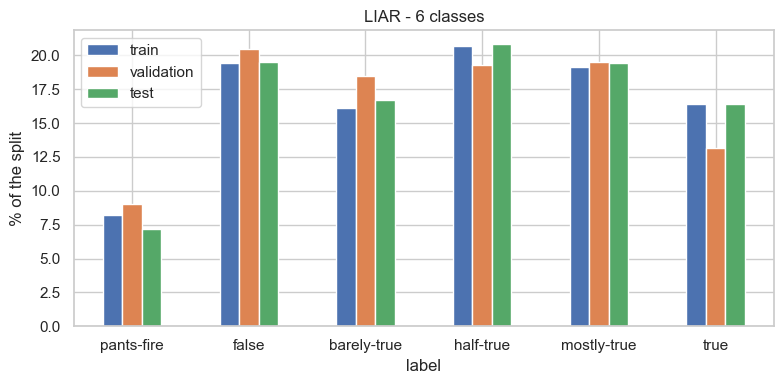

LIAR - binary (1 = fake)


,train,validation,test
label_binary,,,
0,5772 (56.2%),668 (52.0%),727 (56.7%)
1,4497 (43.8%),616 (48.0%),556 (43.3%)


Imbalance ratio (largest / smallest class): {'train': 1.28, 'validation': 1.08, 'test': 1.31}


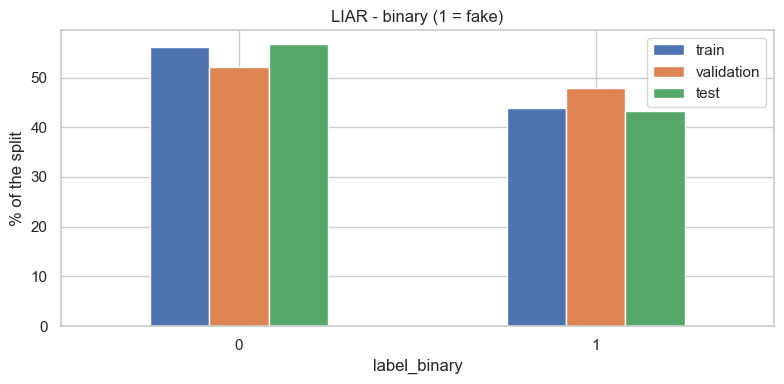

In [6]:
_ = class_distribution(liar, "label", "LIAR - 6 classes", order=LIAR_LABEL_ORDER)
_ = class_distribution(liar, "label_binary", "LIAR - binary (1 = fake)")

**Observations - LIAR (class distribution)**

- With 6 classes, LIAR is **moderately imbalanced**: `pants-fire` is the rare class (8.2% of train) while the other
  five classes are between 16% and 21%. The imbalance ratio is 2.5 in train, 2.3 in validation and 2.9 in test.
- The three splits have **almost the same distribution**, with a small shift in validation: fewer `true`
  (13.2% vs 16.4% in train) and more `barely-true` (18.5% vs 16.1%). In binary, validation is 48.0% fake vs 43.8%
  in train and 43.3% in test. This is small, but it means validation scores can be slightly different from test scores.
- The binary version is close to balanced (56% real / 44% fake, ratio ≈ 1.3).
- **Conclusion on the metric:** accuracy would hide poor performance on `pants-fire`, so the main metric is **macro-F1**
  (same weight for every class), with per-class F1 reported next to it.

## 1.4 Text length

For each text we count characters and words (split on spaces), then compare classes.

The column **% over ~512 tokens** matters for transformer models: BERT-like models accept at most 512 tokens.
English words are about 1.3 tokens on average, so 512 tokens ≈ **380 words**. This is an approximation;
the exact number needs the real tokenizer. If a large share of ISOT articles is longer than that,
we need a strategy (truncation, head+tail, chunking).

In [7]:
APPROX_WORDS_FOR_512_TOKENS = 380


def text_length_stats(df, text_col, label_col, title="", order=None):
    lengths = pd.DataFrame({
        "n_chars": df[text_col].fillna("").str.len(),
        "n_words": df[text_col].fillna("").str.split().str.len(),
        label_col: df[label_col],
    })

    stats = lengths.groupby(label_col)["n_words"].describe(percentiles=[0.5, 0.95]).round(1)
    stats["% over ~512 tokens"] = (
        (lengths["n_words"] > APPROX_WORDS_FOR_512_TOKENS).groupby(lengths[label_col]).mean() * 100
    ).round(1)
    if order is not None:
        stats = stats.loc[order]
    print(title, "- number of words per text")
    display(stats)

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    sns.histplot(data=lengths, x="n_words", hue=label_col, bins=60, stat="density",
                 common_norm=False, element="step", ax=axes[0], hue_order=order)
    axes[0].set_xlim(0, lengths["n_words"].quantile(0.99))   # hide the extreme 1% to keep it readable
    axes[0].set_title(f"{title} - length distribution")
    sns.boxplot(data=lengths, x=label_col, y="n_words", order=order, showfliers=False, ax=axes[1])
    axes[1].set_title(f"{title} - length per class (outliers hidden)")
    plt.tight_layout()
    plt.show()
    return lengths

LIAR train - number of words per text


,count,mean,std,min,50%,95%,max,% over ~512 tokens
label,,,,,,,,
pants-fire,842.0,17.1,7.5,3.0,16.0,31.0,49.0,0.0
false,1998.0,16.8,7.6,2.0,15.0,31.0,60.0,0.0
barely-true,1657.0,18.1,7.8,4.0,17.0,32.0,57.0,0.0
half-true,2123.0,18.8,8.0,2.0,18.0,34.0,60.0,0.0
mostly-true,1966.0,18.2,7.7,3.0,17.0,33.0,65.0,0.0
true,1683.0,17.9,7.6,2.0,16.0,32.0,66.0,0.0


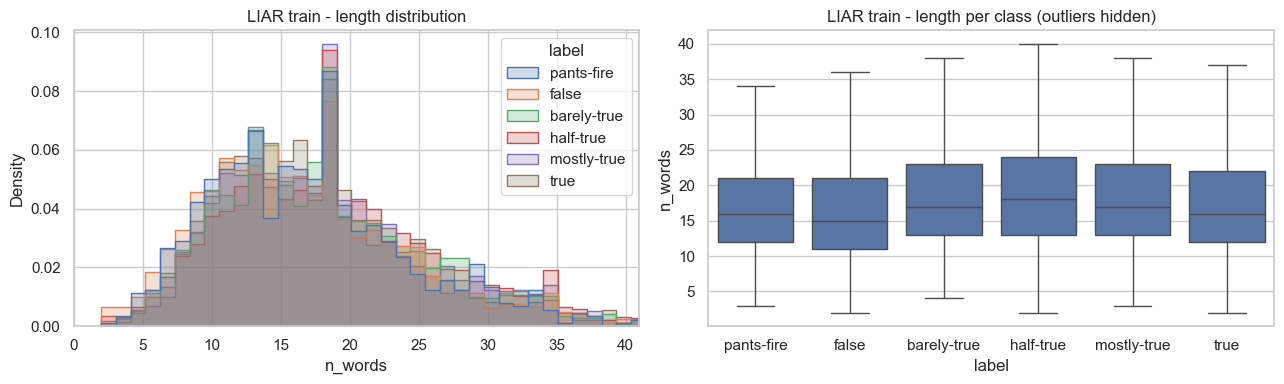

In [8]:
_ = text_length_stats(liar["train"], "statement", "label", "LIAR train", order=LIAR_LABEL_ORDER)

**Observations - LIAR (text length)**

- LIAR statements are **very short**: about 17-19 words on average, median 15-18 words, 95% of statements under
  ~34 words. It is one sentence, so there is little context for a model to use.
- Length is **almost the same in every class** (means between 16.8 and 18.8 words): `half-true` is slightly longer,
  `false` and `pants-fire` slightly shorter, but the difference is too small to be a useful shortcut.
- **No statement is over ~512 tokens** (max 66 words), so transformers can read every statement without truncation.

## 1.5 Vocabulary

`tokenize()` is a simple shared tokenizer: lowercase, then keep sequences of letters / digits / apostrophes.
It is only for exploration; preprocessing choices are studied properly in the A2 notebook.

`vocabulary_stats()` reports:
- **vocabulary size** and **type/token ratio** (distinct words / total words: lexical diversity);
- **hapax share**: % of the vocabulary seen only once (a long tail means many rare words);
- **OOV rate**: % of validation/test words never seen in train. A model only knows the training vocabulary,
  so this matters for word-based models (TF-IDF, static embeddings);
- the **most frequent words per class** (stop words removed so that we see content words).

In [9]:
def tokenize(text):
    return re.findall(r"[a-z0-9']+", str(text).lower())


def vocabulary_stats(train_df, other_splits, text_col, label_col, top_n=15, order=None):
    train_tokens = train_df[text_col].map(tokenize)
    train_counts = Counter(tok for doc in train_tokens for tok in doc)
    n_tokens = sum(train_counts.values())
    n_types = len(train_counts)
    n_hapax = sum(1 for c in train_counts.values() if c == 1)

    print(f"Train tokens: {n_tokens:,} | vocabulary size: {n_types:,} | "
          f"type/token ratio: {n_types / n_tokens:.3f} | hapax: {n_hapax / n_types * 100:.1f}% of the vocabulary")

    # Out-of-vocabulary rate of the other splits with respect to the train vocabulary
    for name, df in other_splits.items():
        tokens = [tok for doc in df[text_col].map(tokenize) for tok in doc]
        oov_tokens = sum(tok not in train_counts for tok in tokens) / len(tokens) * 100
        types = set(tokens)
        oov_types = len(types - train_counts.keys()) / len(types) * 100
        print(f"OOV in {name:<10}: {oov_tokens:.2f}% of tokens, {oov_types:.2f}% of distinct words")

    # Most frequent content words per class
    top_words = {}
    for label, group in train_df.groupby(label_col):
        counts = Counter(tok for doc in train_tokens.loc[group.index] for tok in doc
                         if tok not in ENGLISH_STOP_WORDS and len(tok) > 1)
        top_words[label] = [f"{w} ({c})" for w, c in counts.most_common(top_n)]
    top_words = pd.DataFrame(top_words)
    if order is not None:
        top_words = top_words[order]
    print(f"\nTop {top_n} words per class (stop words removed):")
    display(top_words)
    return train_counts

In [10]:
_ = vocabulary_stats(liar["train"], {"validation": liar["validation"], "test": liar["test"]},
                     "statement", "label", order=LIAR_LABEL_ORDER)

Train tokens: 187,071 | vocabulary size: 12,341 | type/token ratio: 0.066 | hapax: 43.7% of the vocabulary
OOV in validation: 3.16% of tokens, 15.87% of distinct words
OOV in test      : 2.99% of tokens, 15.22% of distinct words

Top 15 words per class (stop words removed):


,pants-fire,false,barely-true,half-true,mostly-true,true
0,says (232),says (472),says (450),says (494),says (402),says (321)
1,obama (102),state (164),percent (153),percent (289),percent (307),percent (244)
2,president (67),obama (154),obama (135),000 (189),000 (178),state (165)
3,health (61),percent (152),state (131),state (176),state (166),years (118)
4,care (59),president (139),tax (120),obama (143),year (150),year (105)
5,barack (57),health (138),000 (114),year (142),tax (150),tax (103)
6,tax (53),tax (132),health (107),jobs (141),million (140),000 (101)
7,said (49),care (119),president (105),years (135),people (137),states (97)
8,people (49),000 (119),care (104),million (134),states (130),health (91)
9,percent (46),years (111),people (104),tax (133),years (127),million (82)


**Observations - LIAR (vocabulary)**

- Train has 187k tokens and a vocabulary of 12.3k words; **43.7% of the vocabulary appears only once** (hapax),
  so many words are rare names, places and numbers.
- The top words are **the same in every class**: `says`, `percent`, `obama`, `state`, `tax`, `health`, `000`...
  They describe **topics and people** (politics, economy, health care), not truth. `says` is at the top everywhere
  because PolitiFact writes many claims as "Says ...".
- Small differences: `obama`, `president`, `barack`, `care` rank higher in the fake classes (claims about Obama /
  Obamacare), while `percent`, `million`, `billion`, `jobs` rank higher in the true classes (claims with
  numbers). A model can partly learn **who and what the claim is about** instead of whether it is true.
- OOV: about **3% of validation/test tokens** (15-16% of distinct words) are never seen in train. It is moderate:
  most tokens are known, but word-based models (TF-IDF, static embeddings) will miss many rare words.

## 1.6 Duplicates and near-duplicates

Three levels, from strict to loose:
1. **Exact duplicates**: identical text.
2. **Normalized duplicates**: identical after lowercasing and removing punctuation / extra spaces
   (`normalize_for_dedup()`), which catches copies that differ only by formatting.
3. **Near-duplicates across splits**: for each validation/test text, we find the most similar train text
   with **TF-IDF cosine similarity** (1 = same words, 0 = nothing in common). Above 0.9 it is almost the same text.
   The computation is done in chunks of 500 rows so memory stays low.

We also count duplicate groups whose copies have **different labels** (label noise), and most importantly
texts shared between **train and validation/test**: this is **data leakage**. The model would be tested on
texts it has already seen, so the score would be too optimistic.

In [11]:
def normalize_for_dedup(text):
    text = str(text).lower()
    text = re.sub(r"[^a-z0-9 ]", " ", text)      # punctuation -> space
    return re.sub(r"\s+", " ", text).strip()     # collapse spaces


def max_similarity_to_train(train_texts, other_texts, chunk_size=500):
    # For each text in other_texts: highest TF-IDF cosine similarity with any train text, and which one
    vectorizer = TfidfVectorizer(stop_words="english", sublinear_tf=True)
    X_train = vectorizer.fit_transform(train_texts)
    X_other = vectorizer.transform(other_texts)
    best_sim, best_idx = [], []
    for start in range(0, X_other.shape[0], chunk_size):
        sims = X_other[start:start + chunk_size] @ X_train.T          # rows are L2-normalised -> cosine
        best_sim.append(sims.max(axis=1).toarray().ravel())
        best_idx.append(np.asarray(sims.argmax(axis=1)).ravel())
    return np.concatenate(best_sim), np.concatenate(best_idx)


def duplicate_analysis(splits, text_col, label_col, near_threshold=0.9, n_examples=5):
    # 1) Duplicates inside each split
    rows = []
    for name, df in splits.items():
        norm = df[text_col].map(normalize_for_dedup)
        in_dup_group = norm.duplicated(keep=False)
        conflicting = df[in_dup_group].groupby(norm[in_dup_group])[label_col].nunique().gt(1).sum()
        rows.append({"split": name, "rows": len(df),
                     "exact duplicates": df[text_col].duplicated().sum(),
                     "normalized duplicates": norm.duplicated().sum(),
                     "duplicate groups with conflicting labels": conflicting})
    print("Duplicates inside each split:")
    display(pd.DataFrame(rows).set_index("split"))

    # 2) Overlap between the first split (train) and the others = leakage
    names = list(splits)
    if len(names) < 2:
        return
    train = splits[names[0]].reset_index(drop=True)
    train_norm = set(train[text_col].map(normalize_for_dedup))
    rows = []
    for name in names[1:]:
        other = splits[name].reset_index(drop=True)
        exact_overlap = other[text_col].map(normalize_for_dedup).isin(train_norm).sum()
        sim, idx = max_similarity_to_train(train[text_col].fillna(""), other[text_col].fillna(""))
        near = sim >= near_threshold
        rows.append({"split": name, f"same text as in {names[0]}": exact_overlap,
                     f"near-duplicate of {names[0]} (cos >= {near_threshold})": near.sum(),
                     "% near-duplicate": round(near.mean() * 100, 2)})

        # A few examples so we can check by eye that the threshold makes sense
        examples = pd.DataFrame({
            "similarity": sim[near].round(3),
            f"{name} text": other.loc[near, text_col].str[:150].values,
            f"{name} label": other.loc[near, label_col].values,
            f"closest {names[0]} text": train.loc[idx[near], text_col].str[:150].values,
            f"{names[0]} label": train.loc[idx[near], label_col].values,
        }).sort_values("similarity")
        if len(examples):
            print(f"\nExamples of near-duplicates ({name} vs {names[0]}), lowest similarities first:")
            display(examples.head(n_examples))
    print(f"\nOverlap with {names[0]}:")
    display(pd.DataFrame(rows).set_index("split"))

In [12]:
duplicate_analysis(liar, "statement", "label")

Duplicates inside each split:


,rows,exact duplicates,normalized duplicates,duplicate groups with conflicting labels
split,,,,
train,10269,17,21,6
validation,1284,0,1,0
test,1283,0,0,0



Examples of near-duplicates (validation vs train), lowest similarities first:


,similarity,validation text,validation label,closest train text,train label
8,0.918,A hidden provision in Obamacare taxes sporting goods as medical devices.,pants-fire,A hidden provision in the health care law taxes sporting goods as medical devices.,pants-fire
4,0.921,The United states is borrowing more than 40 cents of every dollar we spend.,true,Were borrowing 40 cents of every dollar we spend.,true
3,0.928,"Says Donald Trump thinks that climate change is a hoax, invented by the Chinese.",mostly-true,Says Donald Trump says climate change is a hoax invented by the Chinese.,mostly-true
7,0.931,Bill Nelson was the deciding vote on the health care law.,barely-true,U.S. Sen. Bill Nelson was the deciding vote for the health care law.,barely-true
13,0.940,"In the first year of the Obama administration, more jobs were created in the private sector than in the eight years ...",false,More private-sector jobs were created in the second year of the Obama administration than in the eight years of the ...,half-true



Examples of near-duplicates (test vs train), lowest similarities first:


,similarity,test text,test label,closest train text,train label
3,0.918,The average age of the minimum wage worker is 35 years old.,barely-true,The average minimum wage worker is 35 years old.,barely-true
6,0.934,Says President Barack Obama is a socialist.,pants-fire,Says Barack Obama is a socialist.,pants-fire
5,0.995,Says Newt Gingrich co-sponsored a bill with Nancy Pelosi that would have given $60 million a year to a U.N. program ...,pants-fire,Newt Gingrich co-sponsored a bill with Nancy Pelosi that would have given $60 million a year to a U.N. program suppo...,pants-fire
0,1.000,Says Milken Institute rated San Antonio as nations top-performing local economy.,true,Says Milken Institute rated San Antonio as nations top-performing local economy.,true
2,1.000,"On the new dollar coins, ""'In God We Trust' is gone!""",false,"On new dollar coins, In God We Trust is gone!",false



Overlap with train:


,same text as in train,near-duplicate of train (cos >= 0.9),% near-duplicate
split,,,
validation,7,15,1.17
test,5,9,0.70


**Observations - LIAR (duplicates)**

- Inside train there are **17 exact and 21 normalized duplicates**, and **6 duplicate groups have conflicting labels**.
  Most of them are very short "titles" such as *"On abortion"*, *"On torture"*, *"On support for gay marriage"*:
  these are flip-flop checks where the real claim is not in the text, so the same text gets `true` in one case and
  `false` in another. This is **label noise**: no model can get them right from the text alone.
- **Leakage between official splits:** 7 validation and 5 test statements are the same text as a train statement,
  and 15 validation (1.2%) / 9 test (0.7%) statements are near-duplicates (cosine ≥ 0.9). The examples show
  re-worded versions of the same claim, usually with the same label.
- Not every near-duplicate is the same claim: *"first year of the Obama administration"* (false) vs *"second year"*
  (half-true) is a different fact with high word overlap.
- The leakage is **small (around 1%)**, so we keep the official splits as they are (required by the project), but it
  should be mentioned in the report as a small optimistic bias.

## 1.7 Topic and source distributions (metadata)

`metadata_analysis()` shows, for the most frequent values of a metadata column, the **label distribution**
(each row sums to 100%). If a value is strongly linked to one label (e.g. a speaker who is almost always
"false"), a model using metadata can predict the label **without reading the text**.
So a text-only model and a text + metadata model are not comparable.

In LIAR, `subject` can contain several subjects separated by commas (`"energy,history"`), so we split them
(`explode`) before counting.

In [13]:
def metadata_analysis(df, label_col, columns, top_k=10, order=None, multi_value_cols=("subject",)):
    for col in columns:
        values = df[[col, label_col]].copy()
        values[col] = values[col].fillna("missing").astype(str)
        if col in multi_value_cols:
            values[col] = values[col].str.split(",")
            values = values.explode(col).reset_index(drop=True)   # explode repeats the index
            values[col] = values[col].str.strip()

        top_values = values[col].value_counts().head(top_k)
        sub = values[values[col].isin(top_values.index)]
        table = pd.crosstab(sub[col], sub[label_col], normalize="index") * 100
        table = table.loc[top_values.index]
        if order is not None:
            table = table[[c for c in order if c in table.columns]]
        table.index = [f"{v} (n={top_values[v]})" for v in table.index]

        plt.figure(figsize=(1.3 * table.shape[1] + 4, 0.45 * len(table) + 1.5))
        sns.heatmap(table, annot=True, fmt=".0f", cmap="RdYlGn_r" if order else "Blues", cbar=False)
        plt.title(f"Label distribution (%) for the {top_k} most frequent values of '{col}'")
        plt.ylabel(col)
        plt.tight_layout()
        plt.show()

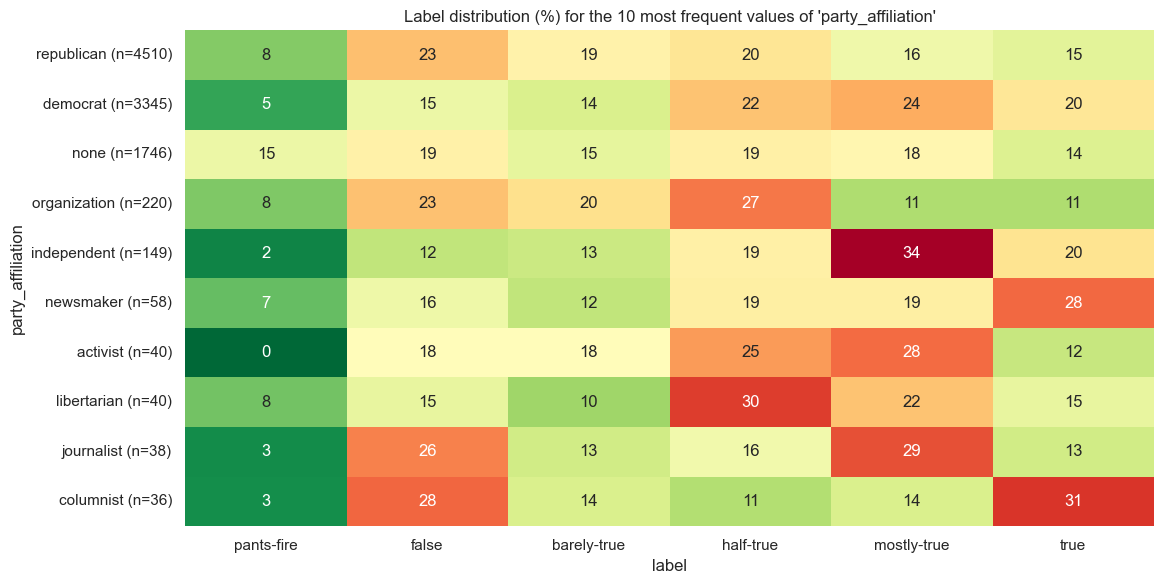

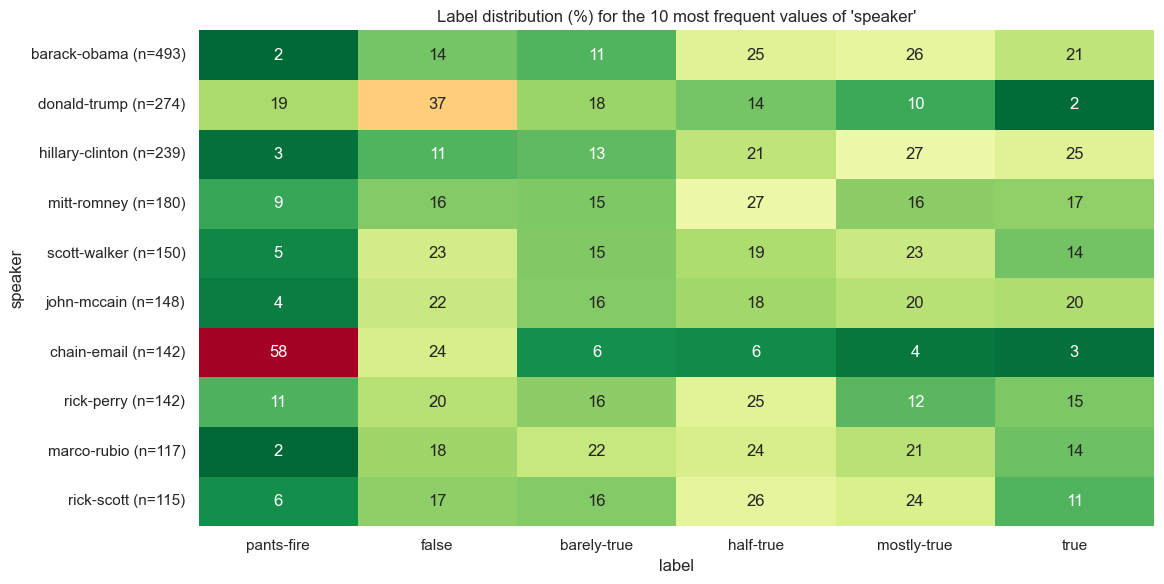

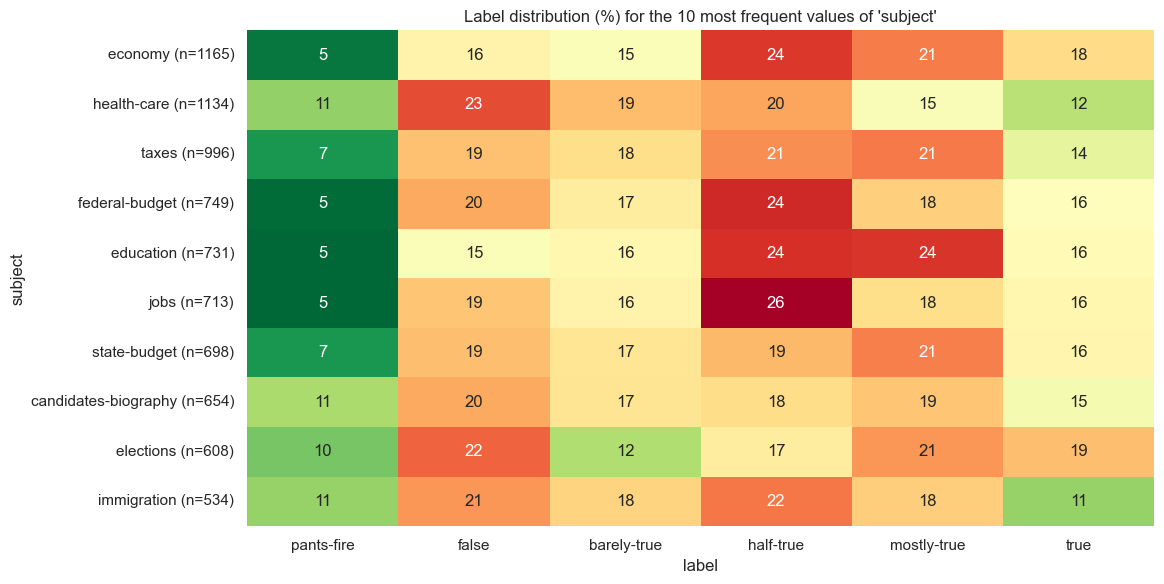

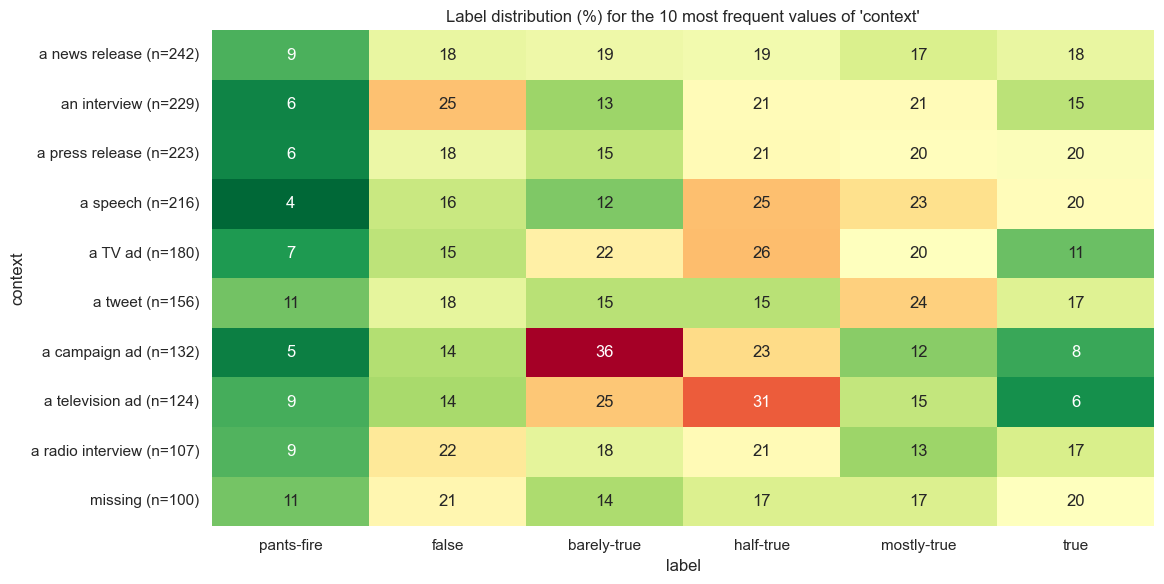

In [14]:
metadata_analysis(liar["train"], "label", ["party_affiliation", "speaker", "subject", "context"],
                  order=LIAR_LABEL_ORDER)

### 1.7b Credit history – a possible leak

LIAR gives, for each speaker, how many of their statements were judged *barely-true*, *false*, *half-true*,
*mostly-true* and *pants-fire*. These counts are known to **include the current statement**, so they can
contain the answer.

`credit_history_analysis()` checks two things:
1. the average **share** of each count in the speaker history, per label. If the diagonal is high
   (false statements come with high `false_counts`), the counts are strongly linked to the label;
2. for each label that has a count column, the % of statements whose own count is 0. If the current statement
   were included, this would be **0%** (the count would be at least 1).

There is no `true_counts` column, which is itself worth noting.

In [15]:
CREDIT_COLUMNS = {"barely-true": "barely_true_counts", "false": "false_counts",
                  "half-true": "half_true_counts", "mostly-true": "mostly_true_counts",
                  "pants-fire": "pants_on_fire_counts"}


def credit_history_analysis(df, label_col="label", order=LIAR_LABEL_ORDER):
    counts = df[list(CREDIT_COLUMNS.values())]
    total = counts.sum(axis=1)
    print(f"Statements whose speaker has no history at all (all counts = 0): {(total == 0).mean() * 100:.1f}%")

    # 1) Share of each count in the speaker's history, averaged per label
    shares = counts.div(total.replace(0, np.nan), axis=0)
    shares[label_col] = df[label_col]
    table = shares.groupby(label_col).mean().loc[order] * 100
    plt.figure(figsize=(8, 4))
    sns.heatmap(table, annot=True, fmt=".0f", cmap="Blues", cbar=False)
    plt.title("Average share (%) of each credit-history count, per statement label")
    plt.tight_layout()
    plt.show()

    # 2) Is the statement's own label already counted in the history?
    rows = []
    for label, col in CREDIT_COLUMNS.items():
        own = df.loc[df[label_col] == label, col]
        rows.append({"label": label, "count column": col, "n statements": len(own),
                     "% with own count = 0": round((own == 0).mean() * 100, 2)})
    display(pd.DataFrame(rows).set_index("label"))

Statements whose speaker has no history at all (all counts = 0): 3.3%


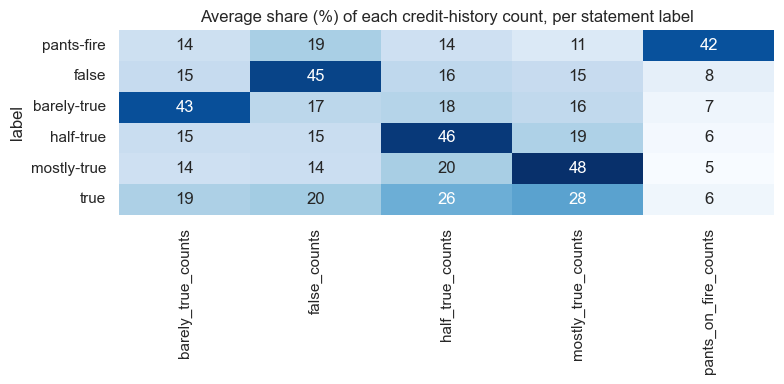

,count column,n statements,% with own count = 0
label,,,
barely-true,barely_true_counts,1657,0.00
false,false_counts,1998,0.95
half-true,half_true_counts,2123,0.42
mostly-true,mostly_true_counts,1966,0.00
pants-fire,pants_on_fire_counts,842,0.00


In [16]:
credit_history_analysis(liar["train"])

**Observations - LIAR (metadata and credit history)**

- **Speaker is strongly linked to the label.** `donald-trump`: 74% of his statements are pants-fire / false /
  barely-true and only 2% are true; `chain-email`: 58% pants-fire. On the other side `barack-obama` and
  `hillary-clinton` are mostly half-true / mostly-true / true (only 2-3% pants-fire).
- **Party:** Republicans have 50% of statements in the three "fake" labels vs 34% for Democrats.
- **Context:** some contexts are linked to a label, e.g. `a campaign ad` is 36% barely-true (vs ~16% overall).
- **Subjects** are more balanced; `health-care` and `immigration` have a bit more false / pants-fire.
- So a model with metadata can predict part of the label **without reading the statement**. A text-only model and a
  text + metadata model must be compared separately.
- **Credit history is a leak.** The heatmap has a strong diagonal: a `false` statement has on average 45% of
  `false_counts` in the speaker's history, vs about 15% for the other counts (same for barely-true 43%, half-true 46%,
  mostly-true 48%, pants-fire 42%). And the share of statements whose own count is 0 is **0%** for barely-true,
  mostly-true and pants-fire (0.95% for false, 0.42% for half-true). The counts **include the current statement**,
  so they partly contain the answer and must not be used as features (or only with this leak clearly stated).
- There is no `true_counts` column, so `true` statements have no diagonal (their history is spread).
- LIAR has no date column, so no temporal analysis is possible on it.

## 1.8 Biases and artifacts

An **artifact** is a surface cue that is correlated with the label but has nothing to do with truth
(e.g. the name of the news agency, a formatting habit). A model can get a high score by learning it,
so we want to know them in advance. Here we look for them in three ways:

1. **Style features per class**: punctuation (`!`, `?`, quotes), uppercase ratio, words in CAPITALS,
   digits, URLs, `@` mentions, `#` hashtags, lost apostrophes (`couldn t`), typographic "curly" quotes
   (’ “ ”) and any non-ASCII character. The last three are about **how the text was scraped/encoded**,
   not about what it says, so they are pure collection artifacts.
2. **First words**: the 3 first tokens of each text, per class. Formatting habits (a dateline, "Says ...")
   usually appear at the start.
3. **Most distinctive tokens**: tokens much more frequent in one class than in the other, measured with a
   smoothed **log-odds ratio**: `log((count_fake + 1) / (total_fake + V)) - log((count_real + 1) / (total_real + V))`.
   Positive = typical of fake, negative = typical of real. Here we **keep case and punctuation** on purpose,
   because that is where artifacts hide (the A2 notebook measures what happens when we remove them).

In [17]:
def style_features(texts):
    texts = texts.fillna("")
    letters = texts.str.count(r"[A-Za-z]").replace(0, np.nan)
    words = texts.str.split().str.len().replace(0, np.nan)
    return pd.DataFrame({
        "! per 100 words": texts.str.count("!") / words * 100,
        "? per 100 words": texts.str.count(r"\?") / words * 100,
        "quotes per 100 words": texts.str.count(r"[\"“”]") / words * 100,
        "uppercase letters %": texts.str.count(r"[A-Z]") / letters * 100,
        "ALL-CAPS words per 100 words": texts.str.count(r"\b[A-Z]{3,}\b") / words * 100,
        "digits per 100 words": texts.str.count(r"\d") / words * 100,
        "% with URL": texts.str.contains(r"http|www\.|\.com", regex=True) * 100,
        "% with @mention": texts.str.contains(r"@\w+", regex=True) * 100,
        "% with #hashtag": texts.str.contains(r"#\w+", regex=True) * 100,
        "% with lost apostrophe (couldn t, don t)": texts.str.contains(r"\b\w+n t\b", regex=True) * 100,
        "% with curly quote / apostrophe (’ “ ”)": texts.str.contains("[’“”]", regex=True) * 100,
        "% with any non-ASCII character": texts.str.contains(r"[^\x00-\x7F]", regex=True) * 100,
    })


def artifact_tokenize(text):
    # Keeps case and punctuation: "WASHINGTON (Reuters) -" -> ["WASHINGTON", "(", "Reuters", ")", "-"]
    return re.findall(r"\w+|[^\w\s]", str(text))


def distinctive_tokens(df, text_col, label_col, positive=1, min_count=20, top_n=20):
    tokens = df[text_col].map(artifact_tokenize)
    pos = Counter(t for doc in tokens[df[label_col] == positive] for t in doc)
    neg = Counter(t for doc in tokens[df[label_col] != positive] for t in doc)
    vocab = [t for t in pos.keys() | neg.keys() if pos[t] + neg[t] >= min_count]
    V, n_pos, n_neg = len(vocab), sum(pos.values()), sum(neg.values())
    scores = pd.DataFrame({
        "token": vocab,
        "count_pos": [pos[t] for t in vocab],
        "count_neg": [neg[t] for t in vocab],
    })
    scores["log_odds"] = (np.log((scores["count_pos"] + 1) / (n_pos + V))
                          - np.log((scores["count_neg"] + 1) / (n_neg + V)))
    scores = scores.sort_values("log_odds")
    return scores.tail(top_n)[::-1].reset_index(drop=True), scores.head(top_n).reset_index(drop=True)


def artifact_analysis(df, text_col, label_col, positive=1, label_names=("real", "fake"), top_n=20):
    named = df[label_col].map({0: label_names[0], 1: label_names[1]})

    # 1) Style features
    feats = style_features(df[text_col])
    print("1) Style features (mean per class):")
    display(feats.groupby(named).mean().T.round(2))

    # 2) First words
    first = df[text_col].fillna("").map(lambda t: " ".join(artifact_tokenize(t)[:3]))
    print("2) Most common first 3 tokens per class (% of the class):")
    starts = {name: (first[named == name].value_counts(normalize=True).head(8) * 100).round(1)
              for name in label_names}
    display(pd.concat({n: s.rename_axis("start").reset_index(name="%") for n, s in starts.items()}, axis=1))

    # 3) Distinctive tokens
    top_pos, top_neg = distinctive_tokens(df, text_col, label_col, positive, top_n=top_n)
    print(f"3) Most distinctive tokens (case and punctuation kept), {label_names[1]} vs {label_names[0]}:")
    display(pd.concat({f"typical of {label_names[1]}": top_pos.round(2),
                       f"typical of {label_names[0]}": top_neg.round(2)}, axis=1))

In [18]:
artifact_analysis(liar["train"], "statement", "label_binary")

1) Style features (mean per class):


label_binary,fake,real
! per 100 words,0.06,0.03
? per 100 words,0.04,0.03
quotes per 100 words,1.24,1.46
uppercase letters %,4.98,4.33
ALL-CAPS words per 100 words,0.40,0.37
digits per 100 words,7.42,10.11
% with URL,0.04,0.00
% with @mention,0.09,0.09
% with #hashtag,0.24,0.23
"% with lost apostrophe (couldn t, don t)",0.00,0.00


2) Most common first 3 tokens per class (% of the class):


real                           fake     
                   start    %                     start    %
0      Says Donald Trump  0.8      Says Hillary Clinton  0.8
1      The United States  0.7                  Says U .  0.8
2       Says Mitt Romney  0.6     Says President Barack  0.7
3   Says Hillary Clinton  0.5         Says Barack Obama  0.7
4                The U .  0.4                Says Gov .  0.6
5               Says U .  0.4                     U . S  0.6
6  Says President Barack  0.3  The Obama administration  0.3
7                  U . S  0.3         Says Donald Trump  0.3

3) Most distinctive tokens (case and punctuation kept), fake vs real:


typical of fake                              typical of real            \
             token count_pos count_neg log_odds           token count_pos   
0         Benghazi        20         6     1.40         decades         2   
1           groups        16         5     1.34          bottom         3   
2        Christian        15         5     1.28           worth         3   
3             team        17         6     1.25      graduation         4   
4              Tom        23         9     1.18              24         4   
5             idea        18         7     1.17             GDP         4   
6            group        27        11     1.15   manufacturing         3   
7          outside        14         6     1.07           grown         4   
8            fight        18         8     1.05           below         6   
9           Muslim        20         9     1.05             row         3   
10             Rep        72        34     1.04           share         3   
11          Walker        72        34     1.04       lobbyists         4   
12         Patrick        15         7     1.00              22         4   
13             Rob        15         7     1.00          Nearly         4   
14         Muslims        17         8     1.00              21         4   
15          charge        20        10     0.95       countries        15   
16       sponsored        18         9     0.95          wealth         4   
17     governments        16         8     0.94          spends         5   
18           favor        16         8     0.94           worst         9   
19        Feingold        16         8     0.94          cities         8   

                       
   count_neg log_odds  
0         23    -1.78  
1         23    -1.49  
2         22    -1.45  
3         26    -1.38  
4         25    -1.35  
5         24    -1.31  
6         19    -1.31  
7         22    -1.22  
8         31    -1.22  
9         17    -1.20  
10        17    -1.20  
11        21    -1.18  
12        21    -1.18  
13        21    -1.18  
14        20    -1.13  
15        64    -1.10  
16        19    -1.08  
17        23    -1.08  
18        38    -1.06  
19        34    -1.05

**Observations - LIAR (biases and artifacts)**

- LIAR has **almost no collection artifacts**: no curly quotes, no lost apostrophes, almost no URLs, `@` or `#`
  (≤ 0.24%), and the style features are very close between fake and real.
- The clearest difference is **digits**: 10.1 per 100 words in real vs 7.4 in fake. True claims more often cite
  numbers (percent, million...). It is a weak cue and partly a real signal (precise claims are easier to verify).
- **First words:** "Says ..." starts statements in both classes (PolitiFact writing convention), so it is not a
  label cue. The top starts are names (Says Donald Trump, Says Hillary Clinton, Says Barack Obama...): it is the
  **speaker/topic** again, not the truth.
- **Distinctive tokens** have small counts (15-70) and are mostly **topics and people**: fake side: Benghazi,
  Muslim(s), Christian, Walker, Feingold, Rep; real side: GDP, manufacturing, wealth, decades, numbers. These are
  topic biases from what PolitiFact chose to check, not words that make a claim false.
- LIAR is therefore **hard to "cheat" on**: no single surface cue separates the classes, which explains why models
  usually get low scores on it.

## 1.9 Splits

We keep the official LIAR train / validation / test splits (as asked in the project), and save their ids in
`data/splits/` so that every team member uses exactly the same rows. These small files go in Git; the data itself does not.

In [19]:
def save_split_ids(splits, prefix, out_dir=SPLITS_DIR):
    out_dir.mkdir(parents=True, exist_ok=True)
    for name, df in splits.items():
        path = out_dir / f"{prefix}_{name}_ids.csv"
        df[["id"]].to_csv(path, index=False)
        print(f"Saved {len(df):>6} ids -> {path.relative_to(ROOT)}")

In [20]:
save_split_ids(liar, "liar")

Saved  10269 ids -> data\splits\liar_train_ids.csv
Saved   1284 ids -> data\splits\liar_validation_ids.csv
Saved   1283 ids -> data\splits\liar_test_ids.csv


---
# Part 2 - ISOT

ISOT: full news articles, `True.csv` (real, mostly Reuters) and `Fake.csv` (fake), with a `subject` and a `date`
column, and **no official split**.

This part reuses the functions defined in Part 1, so **run Part 1 first**.

## 2.1 Loading ISOT

ISOT is two files (`True.csv`, `Fake.csv`) with no id and no split. We create a stable id
(`true_<row>` / `fake_<row>`) so that split files can refer to the articles. Same convention: **1 = fake, 0 = real**.

In [21]:
def load_isot(data_dir=DATA_DIR):
    # Returns one dataframe with both files, a binary label (1 = fake) and a stable id
    parts = []
    for file_name, label, prefix in [("True.csv", 0, "true_"), ("Fake.csv", 1, "fake_")]:
        df = pd.read_csv(data_dir / "ISOT_datasets" / file_name)
        df["label"] = label
        df["id"] = prefix + df.index.astype(str)
        parts.append(df)
    df = pd.concat(parts, ignore_index=True)
    # Some "date" values in Fake.csv are not dates (URLs, titles) -> they become NaT
    df["date_parsed"] = pd.to_datetime(df["date"].str.strip(), errors="coerce", format="mixed")
    return df[["id", "title", "text", "subject", "date", "date_parsed", "label"]]


isot = load_isot()

print(f"ISOT (all): {len(isot):>6} rows")
display(isot.head(3))

ISOT (all):  44898 rows


,id,title,text,subject,date,date_parsed,label
0,true_0,"As U.S. budget fight looms, Republicans flip their fiscal script","WASHINGTON (Reuters) - The head of a conservative Republican faction in the U.S. Congress, who voted this month for ...",politicsNews,"December 31, 2017",2017-12-31,0
1,true_1,U.S. military to accept transgender recruits on Monday: Pentagon,WASHINGTON (Reuters) - Transgender people will be allowed for the first time to enlist in the U.S. military starting...,politicsNews,"December 29, 2017",2017-12-29,0
2,true_2,Senior U.S. Republican senator: 'Let Mr. Mueller do his job',WASHINGTON (Reuters) - The special counsel investigation of links between Russia and President Trump’s 2016 election...,politicsNews,"December 31, 2017",2017-12-31,0


## 2.2 General summary: types, missing values, duplicates

In [22]:
summary(isot, "text", "ISOT (True + Fake)")

------------------------------------------------------------ 
ISOT (True + Fake): 44898 rows, 7 columns
 ------------------------------------------------------------
Missing cells overall: 10 (0.00% of all cells)


,n_missing,pct_missing
date_parsed,10,0.02


Empty or whitespace-only 'text': 631


Duplicated rows (all columns except id): 209
Duplicated 'text' values: 6252

Numeric columns:


,label
count,44898.00
mean,0.52
std,0.50
min,0.00
25%,0.00
50%,1.00
75%,1.00
max,1.00


Number of distinct values per text/categorical column:


,n_unique
id,44898
title,38729
text,38646
subject,8
date,2397


**Observations - ISOT (general summary)**

- No missing values in the raw columns; only **10 dates cannot be parsed** (`date_parsed`): they are URLs written in the
  date column of `Fake.csv` (scraping errors, see 2.7).
- **631 texts are empty** (whitespace only), and **630 of them are fake**. They are not missing as NaN but they are
  useless (often the article was only a video or an image). They are removed before the split.
- **6,252 duplicated texts** (only 38,646 distinct texts for 44,898 rows), **6,027 of them in the fake class**.
  The fake file contains many copies of the same article: **every** duplicated fake text appears under several
  subjects (e.g. once in `politics` and once in `News`), so the copies come from the site's categories, not from new stories.
  Only 209 rows are duplicated on all columns, so the copies usually differ by subject/date/title.
- `subject` has only 8 values and `date` 2,397 values (see 2.7).

## 2.3 Class distribution

There is only one dataframe for now; the class ratio per split is checked again in 2.9.

ISOT (1 = fake)


,all
label,
1,23481 (52.3%)
0,21417 (47.7%)


Imbalance ratio (largest / smallest class): {'all': 1.1}


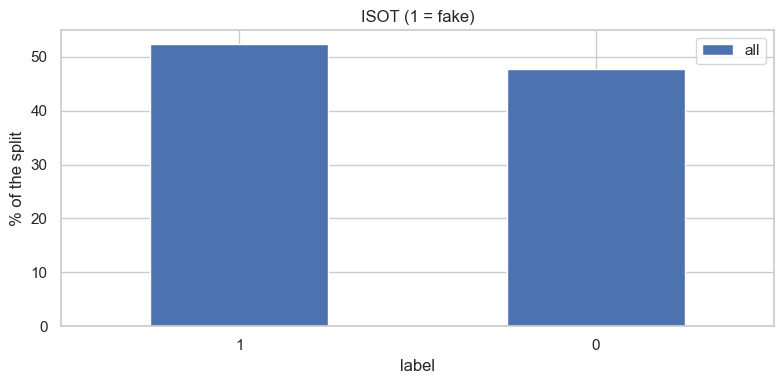

In [23]:
_ = class_distribution({"all": isot}, "label", "ISOT (1 = fake)")

**Observations - ISOT (class distribution)**

- ISOT is **balanced**: 52.3% fake / 47.7% real (ratio 1.1).
- After removing empty texts and duplicates (2.9), the ratio changes to **45.5% fake**, because almost all removed
  rows are fake. It stays close to balanced.
- We keep **macro-F1** as the main metric to be consistent with LIAR; on ISOT accuracy and macro-F1 will be very close.

## 2.4 Text length

ISOT - number of words per text


,count,mean,std,min,50%,95%,max,% over ~512 tokens
label,,,,,,,,
0,21417.0,385.6,274.0,0.0,359.0,894.0,5172.0,46.3
1,23481.0,423.2,408.4,0.0,363.0,926.0,8135.0,46.1


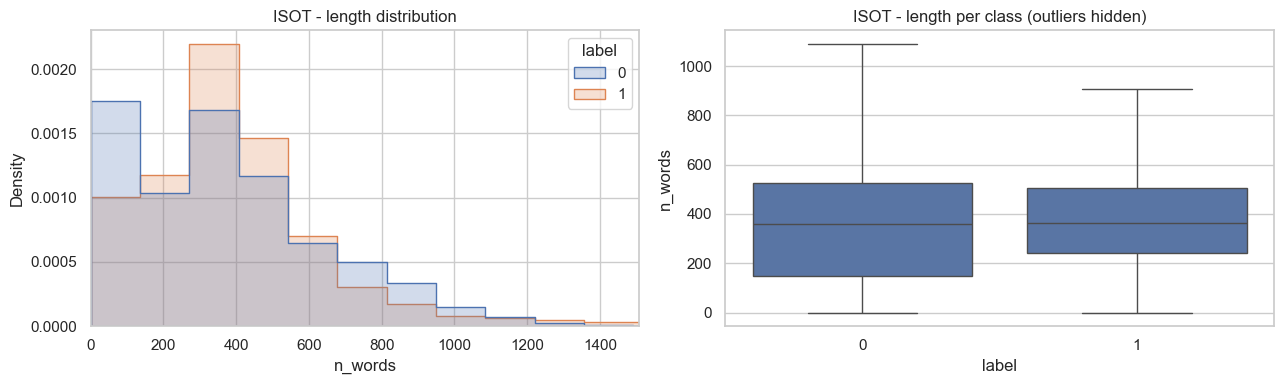

In [24]:
_ = text_length_stats(isot, "text", "label", "ISOT")

**Observations - ISOT (text length)**

- ISOT articles are long: median **359 words (real) and 363 words (fake)**, 95% under ~900 words, max 5,172 (real)
  and 8,135 (fake).
- The medians are almost the same, so **length alone is not a strong shortcut**. Fake articles are a bit longer on
  average (423 vs 386 words) and more variable (std 408 vs 274): fake news has more very long and very short texts
  (including the 630 empty ones).
- About **46% of the articles in both classes are longer than ~512 tokens** (~380 words). Transformers will have to
  truncate almost half of the articles, so a strategy is needed (truncation, head + tail, chunking). Note that the start
  of the article is where the "WASHINGTON (Reuters) -" artifact is (2.8), so simple truncation keeps the artifact.

## 2.5 Vocabulary

For ISOT there is no split yet, so here we only look at the vocabulary of the whole dataset.
The OOV rate is computed again after the split in section 2.9.

In [25]:
_ = vocabulary_stats(isot, {}, "text", "label")

Train tokens: 18,678,805 | vocabulary size: 122,361 | type/token ratio: 0.007 | hapax: 33.6% of the vocabulary



Top 15 words per class (stop words removed):


,0,1
0,said (99062),trump (79175)
1,trump (54645),said (33763)
2,reuters (28974),president (27699)
3,president (28175),people (26563)
4,state (21021),just (20511)
5,government (18843),clinton (19155)
6,new (16915),obama (18763)
7,states (16652),like (18097)
8,house (16640),donald (17678)
9,republican (16243),news (14624)


**Observations - ISOT (vocabulary)**

- Very large corpus: 18.7M tokens, vocabulary of 122k words, 33.6% hapax.
- The top words already show **two different writing styles**:
  - real: `said` (99k, the most frequent word), `reuters`, `told`, `government`, `washington`, `republican`:
    agency news style, reporting what someone **said**, and the agency name itself;
  - fake: `trump`, `clinton`, `obama`, `hillary`, `donald`, and informal words `just`, `like`, `news`: opinion /
    blog style focused on people.
- So the classes differ by **source and style**, and by topic (people vs institutions), more than by truth.
  `reuters` is a pure source artifact.
- OOV after the split (2.9) is very low (**0.58% of validation tokens**), because the corpus is large and
  covers the same period, so vocabulary is not a problem for ISOT.

## 2.6 Duplicates and near-duplicates

For ISOT we only check duplicates **inside** the dataset here (comparing 44k articles with each other
with TF-IDF would be heavy). The duplicates are removed **before** splitting (2.9), then the
train vs validation/test near-duplicate check is run on the new splits.

In [26]:
duplicate_analysis({"all": isot}, "text", "label")

Duplicates inside each split:


,rows,exact duplicates,normalized duplicates,duplicate groups with conflicting labels
split,,,,
all,44898,6252,6531,1


**Observations - ISOT (duplicates)**

- **6,252 exact and 6,531 normalized duplicates** (about 14.5% of the dataset), almost all in the fake class.
- There is **1 duplicate group with conflicting labels**: the group of **empty texts** (empty in both real and fake).
  Once empty texts are removed (2.9), no conflicting group is left.
- ISOT must be **deduplicated before splitting**: with a random split, copies of the same article would end up
  in train and in test, the model would be tested on texts it has already seen, and the score would be too optimistic.
  With ~6k copies this would be a large leak.

## 2.7 Subject and date (metadata)

ISOT has a `subject` column and a `date` column. `temporal_distribution()` plots the number of articles
per month for each class. If real and fake news do not cover the same period, the **date** (and the events of
that period) becomes a shortcut.

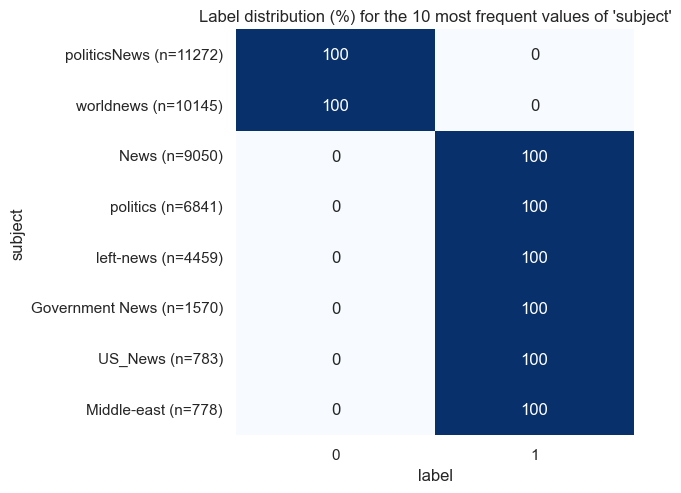

In [27]:
metadata_analysis(isot, "label", ["subject"])

In [28]:
def temporal_distribution(df, date_col, label_col, raw_date_col=None, freq="MS"):
    n_bad = df[date_col].isna().sum()
    print(f"Unparsable dates: {n_bad}")
    if n_bad and raw_date_col is not None:
        print("Examples of unparsable values:", df.loc[df[date_col].isna(), raw_date_col].head(3).tolist())
    display(df.groupby(label_col)[date_col].agg(["min", "max", "count"]))

    monthly = (df.dropna(subset=[date_col])
                 .groupby([pd.Grouper(key=date_col, freq=freq), label_col]).size()
                 .unstack(fill_value=0))
    ax = monthly.plot(figsize=(11, 4))
    ax.set_ylabel("articles per month")
    ax.set_title("Number of articles over time per class")
    plt.tight_layout()
    plt.show()

Unparsable dates: 10
Examples of unparsable values: ['https://100percentfedup.com/served-roy-moore-vietnamletter-veteran-sets-record-straight-honorable-decent-respectable-patriotic-commander-soldier/', 'https://100percentfedup.com/video-hillary-asked-about-trump-i-just-want-to-eat-some-pie/', 'https://100percentfedup.com/12-yr-old-black-conservative-whose-video-to-obama-went-viral-do-you-really-love-america-receives-death-threats-from-left/']


,min,max,count
label,,,
0,2016-01-13,2017-12-31,21417
1,2015-03-31,2018-02-19,23471


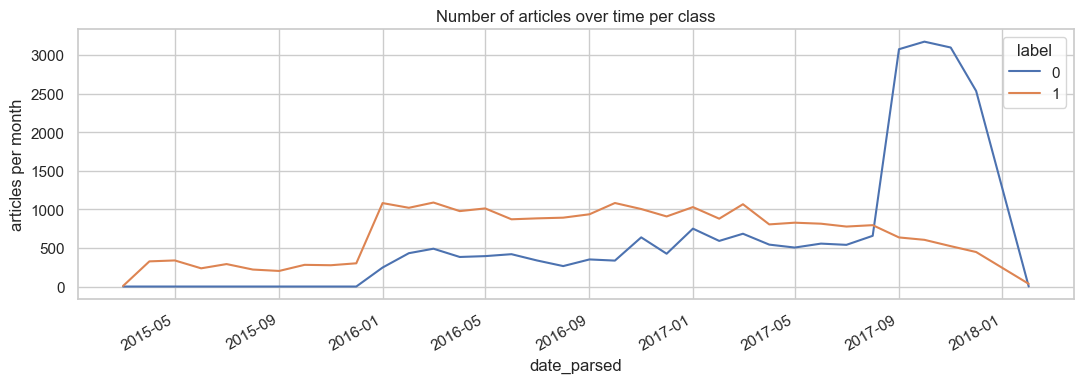

In [29]:
temporal_distribution(isot, "date_parsed", "label", raw_date_col="date")

**Observations - ISOT (subject and date)**

- **`subject` does not overlap at all between classes**: `politicsNews` and `worldnews` are 100% real, and
  `News`, `politics`, `left-news`, `Government News`, `US_News`, `Middle-east` are 100% fake. The subject is a
  **perfect predictor of the label**: it comes from the two websites the data was scraped from, not from the content.
  It must **never be used as a feature**, and it cannot be used to compare topics between classes.
- **The two classes do not cover the same period**:
  - real: 2016-01-13 to 2017-12-31; fake: 2015-03-31 to 2018-02-19;
  - all articles from 2015 (~2,500) and from 2018 are fake;
  - real news is concentrated at the **end of 2017** (13k of the 21k real articles are in Jul-Dec 2017), while fake
    news decreases over time.
- So the **date and the events of the period** are a shortcut: an article about a late-2017 event (Rohingya,
  Catalonia/Puigdemont, Zimbabwe/Mnangagwa: see the distinctive tokens in 2.8) is very likely real just because of
  when it was written.

## 2.8 Biases and artifacts

Same three checks as in 1.8 (style features, first words, distinctive tokens).

In [30]:
artifact_analysis(isot, "text", "label")

1) Style features (mean per class):


label,fake,real
! per 100 words,0.39,0.02
? per 100 words,0.62,0.02
quotes per 100 words,0.05,1.24
uppercase letters %,5.89,5.20
ALL-CAPS words per 100 words,1.60,1.04
digits per 100 words,5.52,3.55
% with URL,26.71,0.89
% with @mention,26.06,1.31
% with #hashtag,13.28,1.11
"% with lost apostrophe (couldn t, don t)",62.57,8.06


2) Most common first 3 tokens per class (% of the class):


real                     fake     
                  start     %              start    %
0  WASHINGTON ( Reuters  30.1  21st Century Wire  3.1
1           ( Reuters )   6.9                     2.7
2            NEW YORK (   3.4     Donald Trump s  1.0
3      LONDON ( Reuters   3.3    Donald Trump is  1.0
4      MOSCOW ( Reuters   2.9         Tune in to  0.9
5      BERLIN ( Reuters   2.4   Donald Trump has  0.8
6     BEIJING ( Reuters   2.0          https : /  0.4
7      BEIRUT ( Reuters   1.6          This is a  0.3

3) Most distinctive tokens (case and punctuation kept), fake vs real:


typical of fake                              typical of real            \
             token count_pos count_neg log_odds           token count_pos   
0         Featured      7867         0     8.79               ’         0   
1              pic      6203         0     8.55               “         0   
2            https      4508         0     8.23               ”         0   
3            Getty      4140         1     7.45               ‘         0   
4           21WIRE      2061         0     7.45         Rakhine         0   
5              Via      3567         2     6.90               –         0   
6               js      1048         0     6.77        Rohingya         2   
7             quot      1000         0     6.73            Zuma         0   
8                f       955         0     6.68      Puigdemont         0   
9              ACR       724         0     6.41         Myanmar         4   
10              id       711         0     6.39             FDP         0   
11    FilesSUPPORT       568         0     6.16         BEIJING         0   
12          Flickr       552         0     6.13               —         0   
13         2017The       549         0     6.13             Suu         0   
14             amp       534         0     6.10             Kyi         0   
15             fjs       522         0     6.08       Mnangagwa         0   
16          Antifa       505         0     6.05             ANC         0   
17          BECOME       498         0     6.03           Rajoy         0   
18       SUBSCRIBE       487         0     6.01          BEIRUT         0   
19     Somodevilla       466         0     5.97          Odinga         0   

                       
   count_neg log_odds  
0      70768   -11.35  
1      54140   -11.08  
2      53861   -11.08  
3       1188    -7.26  
4        897    -6.98  
5        716    -6.76  
6       2054    -6.71  
7        680    -6.70  
8        645    -6.65  
9       2838    -6.52  
10       516    -6.43  
11       503    -6.40  
12       503    -6.40  
13       492    -6.38  
14       491    -6.38  
15       402    -6.18  
16       402    -6.18  
17       386    -6.14  
18       383    -6.13  
19       381    -6.13

**Observations - ISOT (biases and artifacts)**

ISOT is full of collection artifacts. None of them is about truth, they come from **how the two sources were scraped**:

- **Reuters dateline:** **98.6% of real articles** contain `(Reuters)` in their first 100 characters
  (`WASHINGTON (Reuters) -` alone is 30.1%, then NEW YORK, LONDON, MOSCOW...), vs **0.01% of fake** articles.
  Reading the start of the article is enough to classify almost every real article.
- **Encoding of quotes and apostrophes:**
  - curly quotes / apostrophes (’ “ ”) appear in **50.5% of real and 0% of fake** articles; `’` alone appears 70k times
    in real and 0 times in fake (the most distinctive token of the dataset);
  - **lost apostrophes** (`don t`, `Trump s`) appear in **62.6% of fake vs 8.1% of real**: apostrophes were removed
    when the fake articles were collected;
  - any non-ASCII character: 50.7% real vs 0% fake.
- **Web / social media leftovers in fake:** URLs (26.7% vs 0.9%), `@mentions` (26.1% vs 1.3%), `#hashtags`
  (13.3% vs 1.1%), and tokens like `pic`, `https`, `js`, `fjs`, `quot`, `amp` (embedded tweets, JavaScript, HTML codes).
- **Image credits and website names in fake:** `Featured` (image), `Getty`, `Flickr`, `Somodevilla` (a photographer),
  `Via`, `21WIRE` / `21st Century Wire`, `SUBSCRIBE`: all with **0 occurrences in real**.
- **Style:** fake uses more `!` (0.39 vs 0.02 per 100 words), `?` (0.62 vs 0.02) and ALL-CAPS words (1.6 vs 1.0).
  Straight quotes are almost absent in fake (0.05 vs 1.24) because they were stripped too.
- **Period-specific topics in real:** Rohingya, Myanmar, Puigdemont, Mnangagwa, Zuma... (events of late 2017, see 2.7).

These are the cues to remove in the A6 robustness tests (second notebook).
**Compared with LIAR, ISOT is much easier to "cheat" on**: a single feature like "contains `(Reuters)`" or "contains a
curly quote" would already separate most articles, so a very high ISOT score does not prove that a model understands
fake news.

## 2.9 Splits

**ISOT** has no official split, so we design one in `make_isot_split()`:
1. **remove empty texts** (nothing to classify);
2. **deduplicate before splitting** on the normalized text, keeping the first copy. If we split first,
   two copies of the same article could end up in train and in test → leakage. Groups of copies with
   *conflicting* labels are dropped completely (we cannot know the right label);
3. **stratified split 80 / 10 / 10** with `SEED = 42`. Stratified = each split keeps the same real/fake ratio.
   `train_test_split` only makes 2 parts, so we call it twice: 80 / 20, then the 20 is cut in half;
4. **save the ids** (`isot_train_ids.csv`, ...). These small files go in Git; the data itself does not.

`check_splits()` then verifies that the splits do not overlap and that the class ratio is the same everywhere.

In [31]:
def make_isot_split(df, text_col="text", label_col="label", seed=SEED, val_size=0.1, test_size=0.1):
    n_start = len(df)

    # 1) Empty texts
    df = df[df[text_col].fillna("").str.strip() != ""].copy()
    n_empty = n_start - len(df)

    # 2) Deduplicate on the normalized text
    df["norm"] = df[text_col].map(normalize_for_dedup)
    labels_per_text = df.groupby("norm")[label_col].nunique()
    conflicting = labels_per_text[labels_per_text > 1].index
    n_conflict = df["norm"].isin(conflicting).sum()
    df = df[~df["norm"].isin(conflicting)]
    n_before_dedup = len(df)
    df = df.drop_duplicates(subset="norm", keep="first").drop(columns="norm")
    n_dup = n_before_dedup - len(df)

    print(f"Start: {n_start} | empty texts removed: {n_empty} | rows in conflicting-label groups removed: "
          f"{n_conflict} | duplicates removed: {n_dup} | kept: {len(df)}")

    # 3) Stratified 80 / 10 / 10 split, done in two steps
    train, rest = train_test_split(df, test_size=val_size + test_size,
                                   stratify=df[label_col], random_state=seed)
    val, test = train_test_split(rest, test_size=test_size / (val_size + test_size),
                                 stratify=rest[label_col], random_state=seed)
    return {"train": train, "validation": val, "test": test}


def check_splits(splits, label_col):
    ids = {name: set(df["id"]) for name, df in splits.items()}
    names = list(ids)
    for i, a in enumerate(names):
        for b in names[i + 1:]:
            print(f"ids shared by {a} and {b}: {len(ids[a] & ids[b])}")
    display(pd.DataFrame({name: {"rows": len(df), "% fake": round(df[label_col].mean() * 100, 2)}
                          for name, df in splits.items()}))

In [32]:
isot_splits = make_isot_split(isot)
check_splits(isot_splits, "label")
save_split_ids(isot_splits, "isot")

Start: 44898 | empty texts removed: 631 | rows in conflicting-label groups removed: 0 | duplicates removed: 5901 | kept: 38366


ids shared by train and validation: 0
ids shared by train and test: 0
ids shared by validation and test: 0


,train,validation,test
rows,30692.00,3837.00,3837.00
% fake,45.47,45.48,45.45


Saved  30692 ids -> data\splits\isot_train_ids.csv
Saved   3837 ids -> data\splits\isot_validation_ids.csv
Saved   3837 ids -> data\splits\isot_test_ids.csv


Now that ISOT has a train split, we can check the vocabulary OOV rate and run the near-duplicate check
between train and validation / test (this is the TF-IDF comparison, it can take a minute).

In [33]:
_ = vocabulary_stats(isot_splits["train"],
                     {"validation": isot_splits["validation"], "test": isot_splits["test"]},
                     "text", "label", top_n=10)
duplicate_analysis(isot_splits, "text", "label")

Train tokens: 12,740,905 | vocabulary size: 109,342 | type/token ratio: 0.009 | hapax: 42.7% of the vocabulary


OOV in validation: 0.58% of tokens, 16.48% of distinct words


OOV in test      : 0.55% of tokens, 15.76% of distinct words



Top 10 words per class (stop words removed):


,0,1
0,said (77405),trump (54766)
1,trump (42320),said (19804)
2,reuters (22654),people (17162)
3,president (21910),president (16658)
4,state (16346),just (13533)
5,government (14737),donald (12314)
6,new (13232),like (11546)
7,house (13104),clinton (10926)
8,republican (12943),obama (10559)
9,states (12797),time (8673)


Duplicates inside each split:


... (3 outputs left out)


Examples of near-duplicates (test vs train), lowest similarities first:


,similarity,test text,test label,closest train text,train label
32,0.901,"(Reuters) - A few hours after President Donald Trump said there was no chaos in the White House, the administration ...",0,(Reuters) - U.S. Health and Human Services Secretary Tom Price resigned under pressure from President Donald Trump o...,0
19,0.906,White House Chief of Staff John Kelly says he was stunned to learn that Congresswoman Frederica Wilson listened in o...,1,Sounds to me like Gen. Kelly got it right. This portion of her speech seems to emphasize her role in getting the nam...,1
33,0.910,Remember Fusion GPS (please see our previous report on this below)? They are the opposition research firm behind the...,1,"During congressional testimony, the CEO of Hermitage Capital was speaking about the Foreign Agents Registration Act...",1
0,0.916,"Last week, President Trump totally humiliated ABC News on Twitter, as he pointed out their embarrassing attempt at ...",1,WOW! MEGYN KELLY IS CLEARLY DESPERATE FOR RATINGS You won t believe this interview. Megyn Kelly keeps attacking Alab...,1
22,0.916,Steyn: Now Hillary knows how Bill s victims feel Haha! Mark Steyn was awesome tonight on Tucker Carlson:Oh my gosh!...,1,This story is from 2006 and is the first in a long series of Hillary s lies that we ll be exposing over the next cou...,1



Overlap with train:


,same text as in train,near-duplicate of train (cos >= 0.9),% near-duplicate
split,,,
validation,0,32,0.83
test,0,34,0.89


**Observations - ISOT (splits)**

- From 44,898 rows: **631 empty texts** and **5,901 duplicates** were removed, **0 rows** in conflicting-label groups
  (the only conflicting group was the empty texts). **38,366 articles are kept** (85.5%).
- Final splits: **train 30,692 / validation 3,837 / test 3,837** (80 / 10 / 10), no id shared between splits, and
  the same class ratio everywhere (**45.5% fake**). These sizes go in `DECISIONS.md`.
- After deduplication there is **no exact overlap** left, and only **32 validation (0.83%) and 34 test (0.89%)
  near-duplicates** of train (cosine ≥ 0.9). The examples (0.90-0.92) are **not copies**: they are different articles
  about the **same story** (Michael Flynn, two NAFTA negotiation rounds, the tax bill), with the same label.
  The 0.9 threshold and the dedup are therefore enough; the remaining overlap is "same news event" overlap that
  a random split cannot avoid (a time-based split would reduce it).
- OOV of validation/test vs train is very low (0.58% / 0.55% of tokens).

**How teammates load the splits:**
```python
ids = pd.read_csv("data/splits/isot_train_ids.csv")["id"]
isot_train = isot[isot["id"].isin(ids)]
```